Columns loaded: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed', 'y']
Feature matrix shape: (41188, 53)
Target vector shape: (41188,)
Train/Test shapes: (30891, 53) (10297, 53) (30891,) (10297,)
Accuracy: 0.8611, AUC: 0.9392
Confusion Matrix:
 [[7843 1294]
 [ 136 1024]]
Classification Report:
               precision    recall  f1-score   support

           0     0.9830    0.8584    0.9165      9137
           1     0.4418    0.8828    0.5888      1160

    accuracy                         0.8611     10297
   macro avg     0.7124    0.8706    0.7526     10297
weighted avg     0.9220    0.8611    0.8795     10297



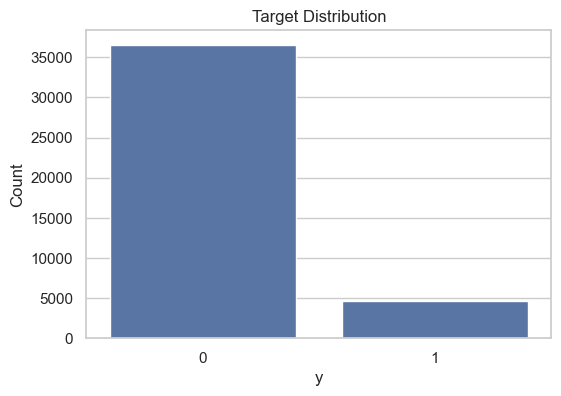

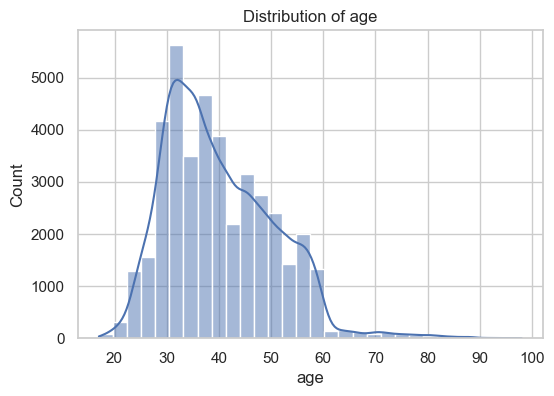

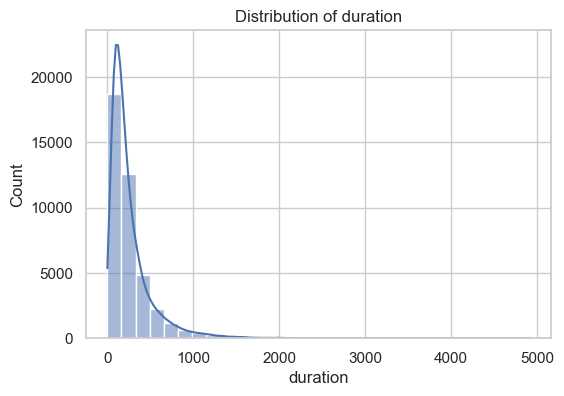

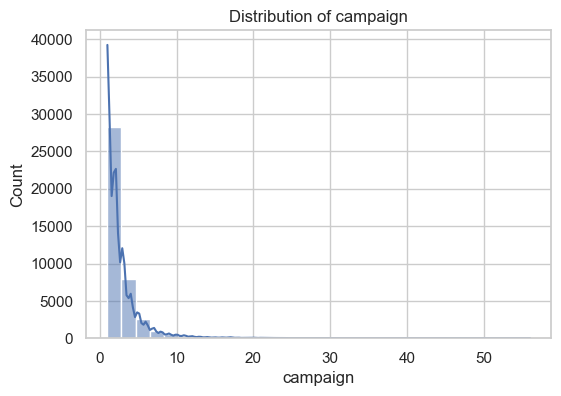

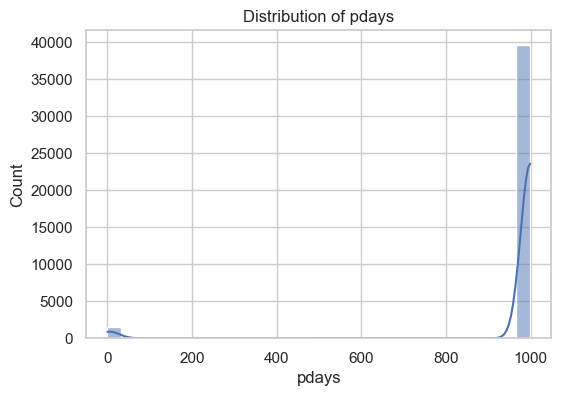

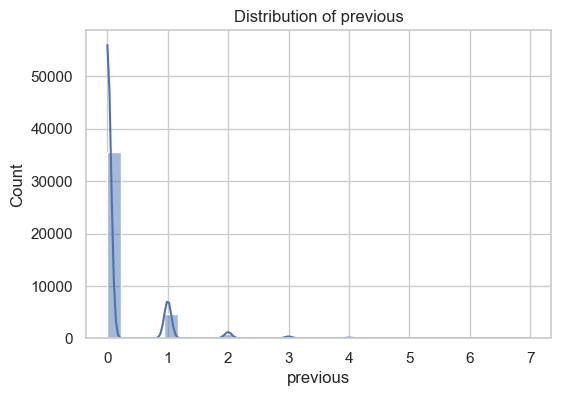

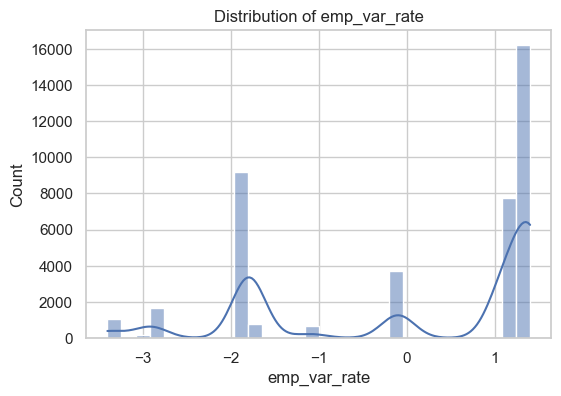

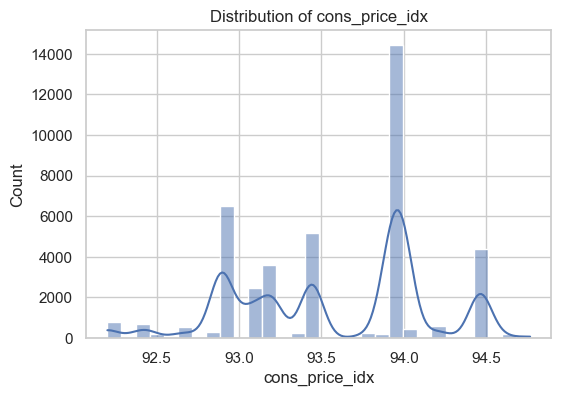

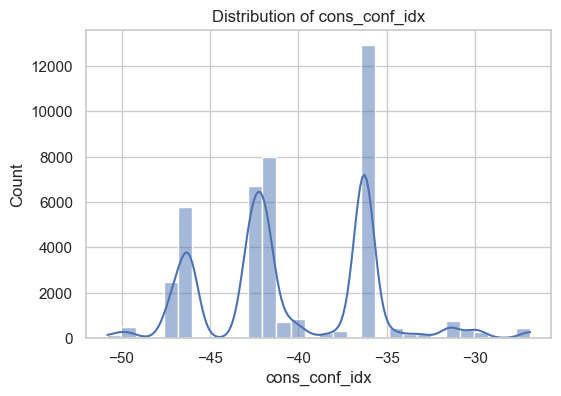

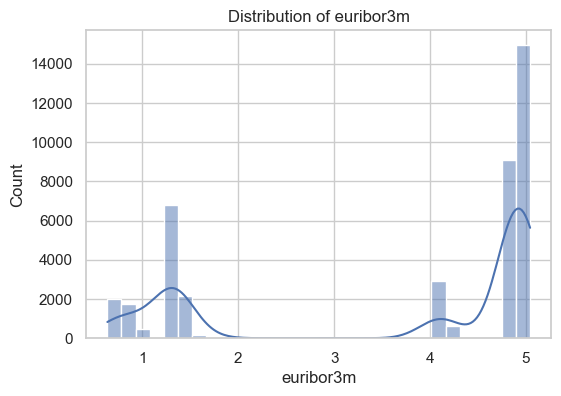

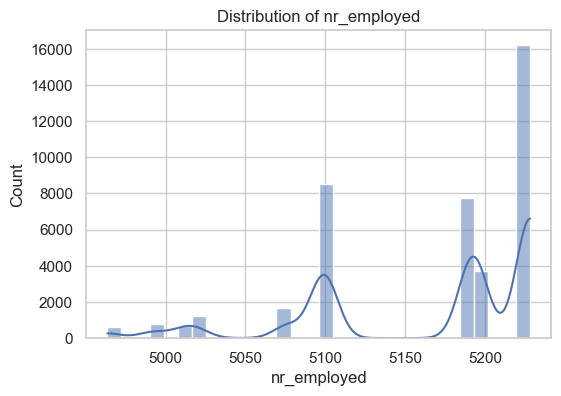

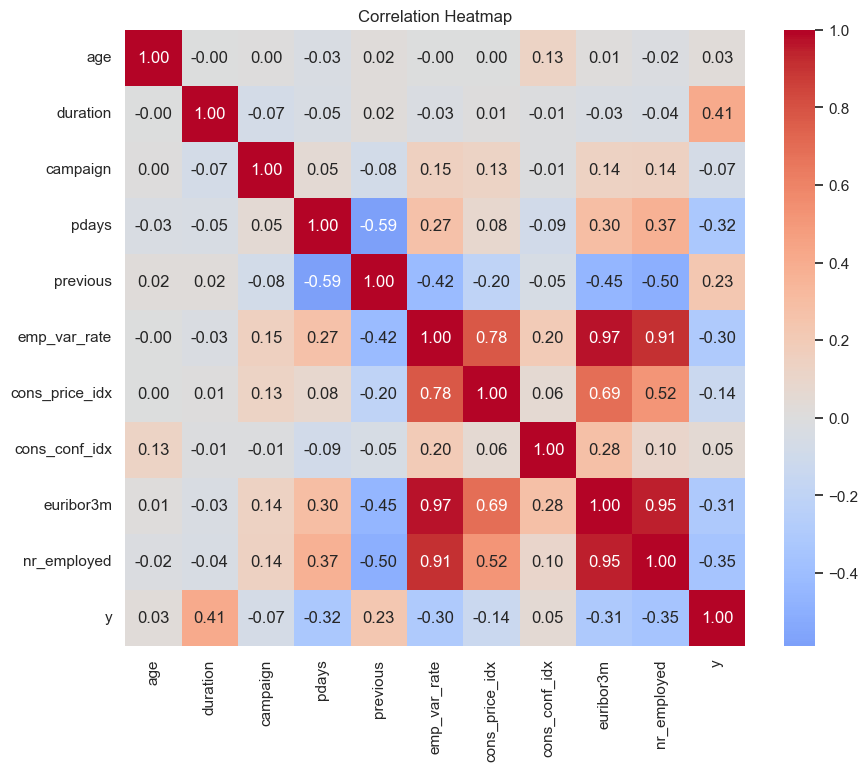

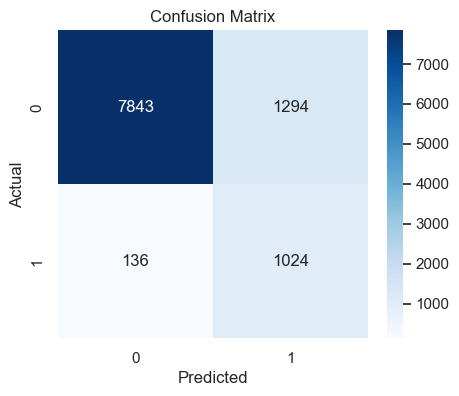

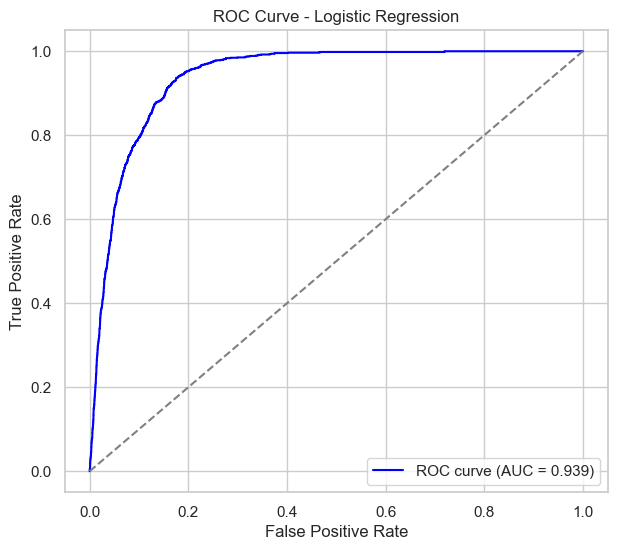

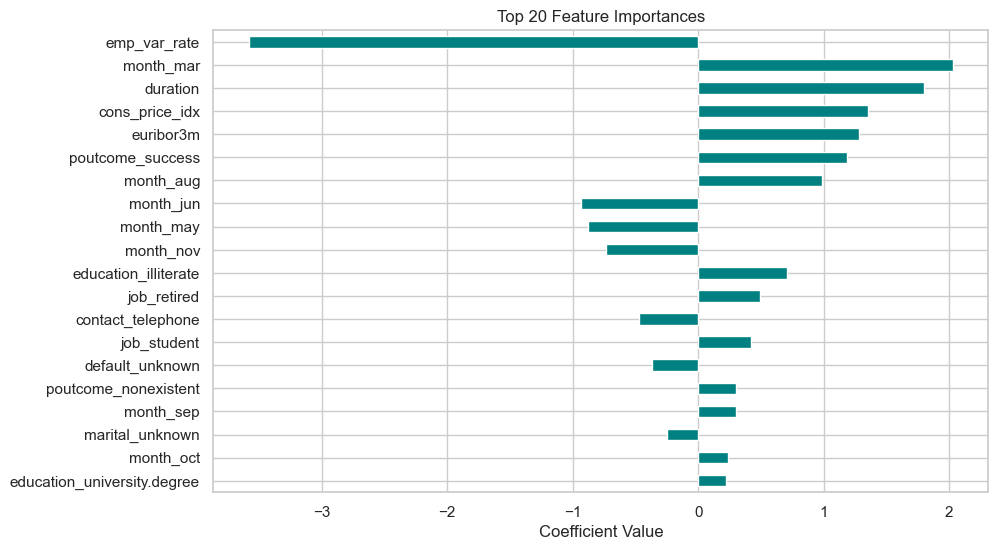

In [3]:
import pandas as pd  # Data manipulation
import numpy as np   # Numeric computations
from sklearn.model_selection import train_test_split  # Train/Test split
from sklearn.preprocessing import StandardScaler      # Feature scaling
from sklearn.linear_model import LogisticRegression   # Logistic Regression model
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc  # Evaluation metrics
import matplotlib.pyplot as plt  # Plotting
import seaborn as sns            # Advanced plotting
from pathlib import Path         # Path handling
import joblib                    # Save models (optional)

# ---------------------------
# 1. Load CSV
# ---------------------------
file_path = "/Users/patrickpatel/Downloads/Lab 12 - Marketing.csv"
df = pd.read_csv(file_path)  # Read CSV into a pandas DataFrame

# Remove whitespace from column names (common CSV issue)
df.columns = df.columns.str.strip()
print("Columns loaded:", df.columns.tolist())

# ---------------------------
# 2. Check target column
# ---------------------------
# The target column is 'y' and already numeric (0/1)
target_col = 'y'
# Ensure target is binary
if df[target_col].nunique() <= 2:
    y = df[target_col].astype(int)  # Convert to integer if not already
else:
    raise ValueError("Target column is not binary (0/1). Check your CSV.")

# ---------------------------
# 3. Identify numeric/categorical
# ---------------------------
# Numeric features used for scaling & modeling
numeric_cols = ['age', 'duration', 'campaign', 'pdays', 'previous',
                'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed']

# All other columns except target are categorical
categorical_cols = [col for col in df.columns if col not in numeric_cols + [target_col]]

# ---------------------------
# 4. Prepare feature matrix
# ---------------------------
# One-hot encode categorical features to numeric dummy variables
X = pd.get_dummies(df[numeric_cols + categorical_cols], drop_first=True)

# Fill missing values with 0
X = X.fillna(0)

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

# ---------------------------
# 5. Train-test split
# ---------------------------
RANDOM_STATE = 42  # For reproducibility
# Split dataset into 75% train, 25% test, maintaining class proportion with stratify
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

print("Train/Test shapes:", X_train.shape, X_test.shape, y_train.shape, y_test.shape)

# ---------------------------
# 6. Scale numeric features
# ---------------------------
# Scale numeric columns to have mean=0, std=1 for better model performance
scaler = StandardScaler()
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])  # Fit on train only
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])        # Apply same scaling to test

# ---------------------------
# 7. Train Logistic Regression
# ---------------------------
# Logistic Regression with class_weight='balanced' to handle imbalance
model = LogisticRegression(max_iter=1000, class_weight='balanced', solver='liblinear', random_state=RANDOM_STATE)
model.fit(X_train, y_train)  # Train model

# ---------------------------
# 8. Evaluate
# ---------------------------
y_pred = model.predict(X_test)           # Predicted labels
y_proba = model.predict_proba(X_test)[:,1]  # Predicted probabilities for ROC/AUC

# Compute metrics
acc = accuracy_score(y_test, y_pred)      # Accuracy
cm = confusion_matrix(y_test, y_pred)     # Confusion Matrix
report = classification_report(y_test, y_pred, digits=4)  # Precision, Recall, F1
fpr, tpr, thresholds = roc_curve(y_test, y_proba)          # ROC Curve
roc_auc = auc(fpr, tpr)                                    # AUC

print(f"Accuracy: {acc:.4f}, AUC: {roc_auc:.4f}")
print("Confusion Matrix:\n", cm)
print("Classification Report:\n", report)

# ---------------------------
# 9. Visualizations
# ---------------------------
sns.set(style="whitegrid")  # Better plot style

# Target distribution plot
plt.figure(figsize=(6,4))
sns.countplot(x=y)
plt.title("Target Distribution")
plt.xlabel("y")
plt.ylabel("Count")
plt.show()

# Histograms of numeric features
for col in numeric_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, bins=30)  # KDE curve adds smooth density
    plt.title(f"Distribution of {col}")
    plt.show()

# Correlation heatmap (numeric + target)
plt.figure(figsize=(10,8))
corr = df[numeric_cols + [target_col]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

# Confusion matrix heatmap
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# ROC curve plot
plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})", color="blue")
plt.plot([0,1],[0,1], linestyle='--', color='gray')  # Diagonal line
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid(True)
plt.show()

# Feature importance (top 20 coefficients)
coefficients = pd.Series(model.coef_[0], index=X.columns).sort_values(key=abs, ascending=False)
plt.figure(figsize=(10,6))
coefficients[:20].plot(kind='barh', color='teal')
plt.gca().invert_yaxis()  # Highest coefficient at top
plt.title("Top 20 Feature Importances")
plt.xlabel("Coefficient Value")
plt.show()
